# Learning Model Evaluation with Iris
### One dataset • Three connected activities
**Aim:** Learn how to check a model fairly, combine several models, and choose a suitable model complexity.

You will predict the species of an Iris flower using four measurements. There are three species: Setosa, Versicolor and Virginica.

| Activity | Question we will answer |
|---|---|
| A. Bootstrapping and cross-validation | Does the model perform well on different samples? |
| B. Bagging and boosting | Can a group of models improve predictions? |
| C. Tree depth | What happens when a model becomes more complex? |

**How to use:** Open this notebook in Google Colab or Jupyter. Run each code cell in order. Read its explanation before moving on. The outputs are included so you can compare them with your run.

Required packages: numpy, pandas, matplotlib and scikit-learn. If needed, install them with `%pip install numpy pandas matplotlib scikit-learn` in a separate cell.

## Step 1: Import the tools
An **import** makes a Python library available. A decision tree predicts a class by asking a sequence of questions about the flower measurements.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# A fixed seed makes our random choices repeatable.
SEED = 42


## Step 2: Load and inspect the flowers
**X** contains the input measurements. **y** contains the correct species labels: 0, 1 or 2. Each row represents one flower.

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

flowers = pd.DataFrame(X, columns=iris.feature_names)
flowers['species'] = iris.target_names[y]
print(flowers.head().to_string(index=False))
print('\nNumber of flowers:', len(X))
print('Missing measurements:', np.isnan(X).sum())
print('Species:', iris.target_names)


 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) species
               5.1               3.5                1.4               0.2  setosa
               4.9               3.0                1.4               0.2  setosa
               4.7               3.2                1.3               0.2  setosa
               4.6               3.1                1.5               0.2  setosa
               5.0               3.6                1.4               0.2  setosa

Number of flowers: 150
Missing measurements: 0
Species: ['setosa' 'versicolor' 'virginica']


Iris contains 150 flowers and has no missing measurements. No filling of missing values is needed. Trees do not require feature scaling.

## Step 3: Keep a final test set aside
Use **120 flowers for learning and validation**, and keep **30 flowers for the final test**. Think of the test set as a final examination. We must not use its answers to choose the model.

`test_size=0.2` reserves 20%. `stratify=y` preserves the proportions of the three species.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print('Flowers available for training and validation:', len(X_train))
print('Flowers reserved for the final test:', len(X_test))


Flowers available for training and validation: 120
Flowers reserved for the final test: 30


## Understand the scores
| Score | Simple meaning |
|---|---|
| Accuracy | Fraction of all predictions that are correct |
| Precision | For a predicted species, how often is that prediction correct? |
| Recall | Of the flowers actually belonging to a species, how many did we find? |
| F1-score | A balance between precision and recall |

**Macro** means calculate a score separately for each species, then take the average. All three species receive equal importance. Higher scores are better; 1.0 means perfect performance on the evaluated observations.

The small function below avoids repeating our accuracy and F1 calculations. `labels=[0,1,2]` keeps all three species in the macro average. `zero_division=0` handles a class with no predicted examples.

In [4]:
def evaluate_predictions(actual, predicted):
    accuracy = accuracy_score(actual, predicted)
    f1 = f1_score(actual, predicted, labels=[0, 1, 2],
                  average='macro', zero_division=0)
    return accuracy, f1


## Activity A1: Bootstrapping
Imagine drawing flower cards from a box. After each draw, **put the card back**. You may draw the same card more than once.

A bootstrap training sample has 120 draws, but some flowers repeat. The flowers never drawn are called **out-of-bag (OOB)** flowers. They are used to evaluate that model.

### Step 4: See one bootstrap sample
We draw row numbers first, then use those row numbers to select flowers. `np.unique` removes duplicate row numbers. `np.setdiff1d` finds row numbers absent from the sample.

In [5]:
rng = np.random.default_rng(SEED)
number_of_flowers = len(X_train)
all_indices = np.arange(number_of_flowers)

sample_indices = rng.choice(all_indices, size=number_of_flowers, replace=True)
unique_indices = np.unique(sample_indices)
oob_indices = np.setdiff1d(all_indices, unique_indices)

print('First 20 sampled row numbers:', sample_indices[:20])
print('Total draws:', len(sample_indices))
print('Different flowers selected:', len(unique_indices))
print('Flowers left for OOB evaluation:', len(oob_indices))


First 20 sampled row numbers: [ 10  92  78  52  51 103  10  83  24  11  63 117  88  91  86  94  61  15
 100  54]
Total draws: 120
Different flowers selected: 79
Flowers left for OOB evaluation: 41


### Step 5: Repeat bootstrapping 100 times
Each repetition trains a fresh depth-3 decision tree. **Fit on sampled flowers; evaluate on OOB flowers.** A depth limit controls how many question levels the tree may use.

In [6]:
# Restart the generator so this activity always uses the same 100 samples.
rng = np.random.default_rng(SEED)
bootstrap_accuracy = []
bootstrap_f1 = []

for repetition in range(100):
    sample_indices = rng.choice(all_indices, size=number_of_flowers, replace=True)
    oob_indices = np.setdiff1d(all_indices, np.unique(sample_indices))

    # An empty OOB set cannot be evaluated.
    if len(oob_indices) == 0:
        continue

    model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    model.fit(X_train[sample_indices], y_train[sample_indices])
    predictions = model.predict(X_train[oob_indices])
    accuracy, f1 = evaluate_predictions(y_train[oob_indices], predictions)

    bootstrap_accuracy.append(accuracy)
    bootstrap_f1.append(f1)

print('Bootstrap repetitions evaluated:', len(bootstrap_accuracy))
print('Mean accuracy:', round(np.mean(bootstrap_accuracy), 4))
print('Mean macro F1:', round(np.mean(bootstrap_f1), 4))


Bootstrap repetitions evaluated: 100
Mean accuracy: 0.9441
Mean macro F1: 0.9426


## Activity A2: Five-fold cross-validation
Divide the 120 training flowers into five groups, called **folds**. Train on four groups and validate on the remaining group. Repeat five times, changing the validation group each time.

Every flower is used for validation once. **Stratified** folds approximately preserve the proportions of the species.

### Step 6: Train and evaluate one fold at a time
The classifier is again a depth-3 tree so that the resampling methods use the same model settings.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_accuracy = []
cv_f1 = []

for fold, (fit_indices, validation_indices) in enumerate(cv.split(X_train, y_train), start=1):
    model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    model.fit(X_train[fit_indices], y_train[fit_indices])
    predictions = model.predict(X_train[validation_indices])
    accuracy, f1 = evaluate_predictions(y_train[validation_indices], predictions)

    cv_accuracy.append(accuracy)
    cv_f1.append(f1)
    print(f'Fold {fold}: accuracy = {accuracy:.4f}, macro F1 = {f1:.4f}')


Fold 1: accuracy = 0.9583, macro F1 = 0.9582
Fold 2: accuracy = 1.0000, macro F1 = 1.0000
Fold 3: accuracy = 0.9583, macro F1 = 0.9582
Fold 4: accuracy = 0.9583, macro F1 = 0.9582
Fold 5: accuracy = 0.9167, macro F1 = 0.9153


### Step 7: Compare the two methods
**Mean** is the average score. **Standard deviation (SD)** describes how much scores vary across the repetitions or folds. A larger SD means more variation in those scores. These SDs are descriptive; they are not confidence intervals and do not prove one method is more reliable.

                 Method  Mean accuracy  Accuracy SD  Mean macro F1  Macro F1 SD
          Bootstrap OOB         0.9441       0.0330         0.9426       0.0337
5-fold cross-validation         0.9583       0.0295         0.9580       0.0299


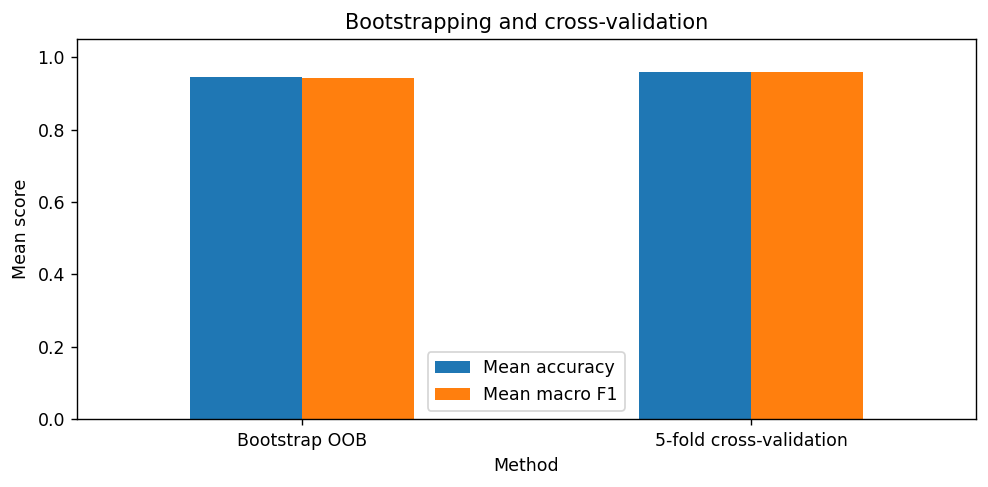

In [8]:
resampling_table = pd.DataFrame({
    'Method': ['Bootstrap OOB', '5-fold cross-validation'],
    'Mean accuracy': [np.mean(bootstrap_accuracy), np.mean(cv_accuracy)],
    'Accuracy SD': [np.std(bootstrap_accuracy, ddof=1), np.std(cv_accuracy, ddof=1)],
    'Mean macro F1': [np.mean(bootstrap_f1), np.mean(cv_f1)],
    'Macro F1 SD': [np.std(bootstrap_f1, ddof=1), np.std(cv_f1, ddof=1)]
})
print(resampling_table.round(4).to_string(index=False))

resampling_table.plot(x='Method', y=['Mean accuracy', 'Mean macro F1'],
                      kind='bar', ylim=(0, 1.05), rot=0, figsize=(8, 4))
plt.ylabel('Mean score')
plt.title('Bootstrapping and cross-validation')
plt.tight_layout()
plt.show()


**Read the output:** With these settings, OOB accuracy is about 0.9441 and CV accuracy is about 0.9583. This does not mean CV makes the classifier better. They evaluate it using different training samples. A bootstrap sample contains fewer unique flowers than a CV training fold.

**Pause and think:** Why would evaluating on the bootstrap training sample give an overly optimistic score?

## Activity C: How complex should a tree be?
We study complexity **before** opening the final test set.

- **Underfitting:** A model is too simple to learn useful patterns. Both training and validation errors may be high.
- **Overfitting:** A model learns training details that do not generalise. Training error is low but validation error may rise.
- **Bias:** Error associated with restrictive assumptions; very simple trees can have high bias.
- **Variance:** Sensitivity to the particular training sample; very deep trees can have high variance.

### Step 8: Try maximum depths from 1 to 10
For each depth, use the same five folds. Record training and validation errors. **Error = 1 − accuracy.** For example, accuracy 0.95 means error 0.05.

The outer loop changes depth. The inner loop changes the validation fold.

In [9]:
depths = range(1, 11)
training_errors = []
validation_errors = []

for depth in depths:
    fold_training_errors = []
    fold_validation_errors = []

    for fit_indices, validation_indices in cv.split(X_train, y_train):
        model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
        model.fit(X_train[fit_indices], y_train[fit_indices])

        training_predictions = model.predict(X_train[fit_indices])
        validation_predictions = model.predict(X_train[validation_indices])
        train_error = 1 - accuracy_score(y_train[fit_indices], training_predictions)
        validation_error = 1 - accuracy_score(y_train[validation_indices], validation_predictions)

        fold_training_errors.append(train_error)
        fold_validation_errors.append(validation_error)

    training_errors.append(np.mean(fold_training_errors))
    validation_errors.append(np.mean(fold_validation_errors))

# argmin gives the position of the smallest validation error.
# Adding 1 converts that position (starting at 0) to a depth (starting at 1).
best_depth = int(np.argmin(validation_errors)) + 1
print('Selected maximum depth:', best_depth)
print(pd.DataFrame({'Depth': list(depths), 'Training error': training_errors,
                    'Validation error': validation_errors}).round(4).to_string(index=False))


Selected maximum depth: 3
 Depth  Training error  Validation error
     1          0.3333            0.3333
     2          0.0333            0.0583
     3          0.0208            0.0417
     4          0.0062            0.0583
     5          0.0021            0.0500
     6          0.0000            0.0500
     7          0.0000            0.0500
     8          0.0000            0.0500
     9          0.0000            0.0500
    10          0.0000            0.0500


### Step 9: Plot the errors
Lower is better here because the graph shows **errors**, not accuracy. Choose depth from validation error. When depths tie, our code chooses the first and therefore shallowest one.

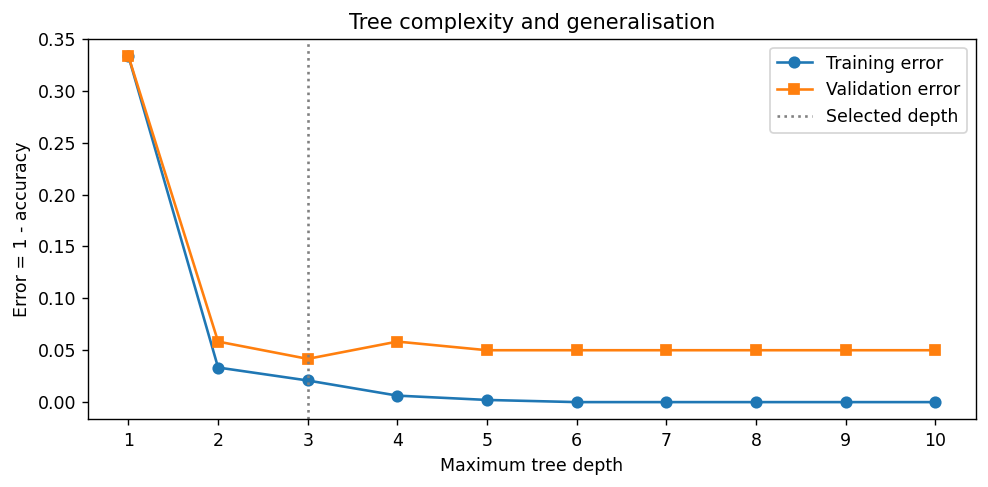

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(depths, training_errors, 'o-', label='Training error')
plt.plot(depths, validation_errors, 's-', label='Validation error')
plt.axvline(best_depth, color='grey', linestyle=':', label='Selected depth')
plt.xticks(list(depths))
plt.xlabel('Maximum tree depth')
plt.ylabel('Error = 1 - accuracy')
plt.title('Tree complexity and generalisation')
plt.legend()
plt.tight_layout()
plt.show()


**Read the graph:** Look for a large error at shallow depths, then see whether validation error improves or rises as depth increases. With this split, depth 3 is selected. Iris is easy to classify, so the curve may flatten rather than show a strong U shape. Report what you observe.

These curves help explain the bias–variance tradeoff; they do **not** directly measure bias and variance.

## Activity B: Combine models with bagging and boosting
| Method | How it works |
|---|---|
| Single tree | One tree predicts the species |
| Bagging | Train many trees on bootstrap samples and combine their predictions |
| AdaBoost | Train small trees sequentially, paying more attention to previously misclassified flowers |

A **decision stump** is a tree with maximum depth 1. Bagging often reduces the variance of deep trees. Boosting can improve weak learners and reduce bias. Neither is guaranteed to improve every dataset.

### Step 10: Create and train the models
`n_estimators=100` asks for up to 100 base models. AdaBoost may stop early. `learning_rate=0.5` controls the contribution of each boosting step. These demonstration settings are fixed, not chosen from the test results.

In [11]:
single_tree = DecisionTreeClassifier(random_state=SEED)

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=SEED),
    n_estimators=100,
    random_state=SEED
)

boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
    n_estimators=100,
    learning_rate=0.5,
    random_state=SEED
)

selected_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)

single_tree.fit(X_train, y_train)
bagging.fit(X_train, y_train)
boosting.fit(X_train, y_train)
selected_tree.fit(X_train, y_train)
print('All four models have been trained.')


All four models have been trained.


### Step 11: Use the reserved test set
We now evaluate the trained models on the same 30 unseen flowers. The loop simply repeats the same scoring instructions for each model. Keep the test results for reporting; do not change settings to improve these particular scores.

In [12]:
model_names = ['Single tree', 'Bagging', 'AdaBoost', 'CV-selected tree']
trained_models = [single_tree, bagging, boosting, selected_tree]
results = []

for name, model in zip(model_names, trained_models):
    predictions = model.predict(X_test)
    accuracy, f1 = evaluate_predictions(y_test, predictions)
    precision = precision_score(y_test, predictions, labels=[0, 1, 2],
                                average='macro', zero_division=0)
    recall = recall_score(y_test, predictions, labels=[0, 1, 2],
                          average='macro', zero_division=0)
    results.append([name, accuracy, precision, recall, f1])

test_table = pd.DataFrame(results, columns=[
    'Model', 'Accuracy', 'Macro precision', 'Macro recall', 'Macro F1'
])
print(test_table.round(4).to_string(index=False))


           Model  Accuracy  Macro precision  Macro recall  Macro F1
     Single tree    0.9333           0.9333        0.9333    0.9333
         Bagging    0.9667           0.9697        0.9667    0.9666
        AdaBoost    0.9667           0.9697        0.9667    0.9666
CV-selected tree    0.9667           0.9697        0.9667    0.9666


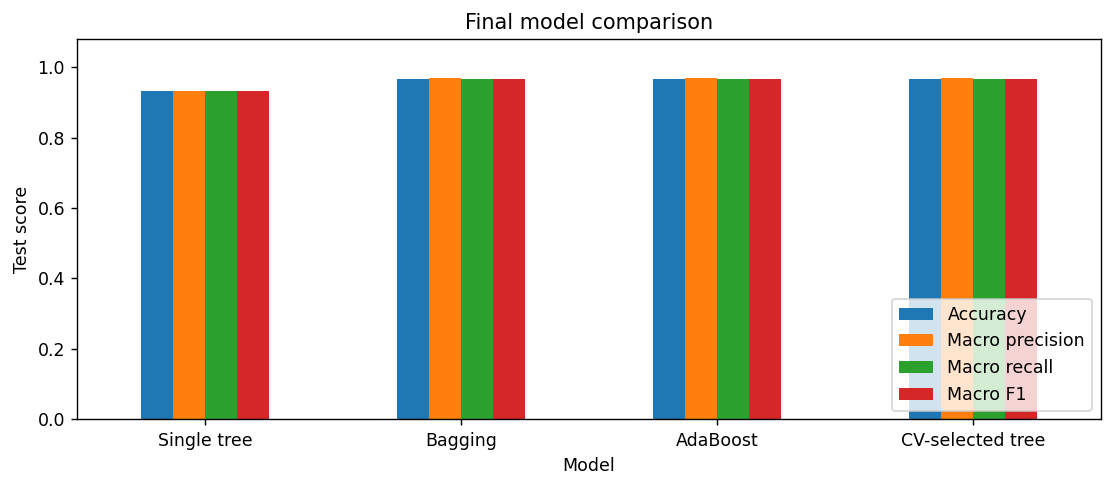

In [13]:
test_table.plot(x='Model', y=['Accuracy', 'Macro precision', 'Macro recall', 'Macro F1'],
                kind='bar', figsize=(9, 4), rot=0, ylim=(0, 1.08))
plt.ylabel('Test score')
plt.title('Final model comparison')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


**Read the result:** In this run, the single tree achieves 93.33% test accuracy. Bagging, AdaBoost and the CV-selected tree each achieve 96.67%. This means 28 versus 29 correct predictions out of 30; the difference is only one flower. The ensembles do not outperform the selected tree in this run.

## What have we learned?
| Technique | Advantage | Limitation |
|---|---|---|
| Bootstrapping | Shows performance across many resampled datasets; useful when studying sampling variation | Repeated rows reduce the number of unique training examples; OOB sets differ in size |
| Cross-validation | Every training observation is validated once; useful for choosing model settings | Requires several model fits; results depend on the folds |
| Bagging | Often stabilises deep decision trees | Uses more computation and is harder to explain than a single tree |
| Boosting | Builds a stronger classifier from small learners | Can focus too much on noisy or unusual examples; depends on settings |
| Depth selection | Helps balance model simplicity and generalisation | The best depth may change with the dataset or split |

**Keep comparisons separate:** Resampling scores describe a fixed depth-3 tree on the training data. Final scores describe models on the reserved test data. These scores come from different evaluation procedures.

## Questions for your lab record
1. What is sampling with replacement? Identify repeated row numbers in Step 4.
2. What are out-of-bag observations, and why do we use them?
3. How many times is each training flower used for validation in 5-fold CV?
4. Compare the mean accuracy and macro F1 of the two resampling methods.
5. How do bagging and boosting differ?
6. Which models have the highest test accuracy? How many extra predictions are correct?
7. Describe the training and validation error curves. Is strong overfitting visible?
8. Why should the final test set be kept separate from depth selection?

**Suggested conclusion:** Write 4–5 sentences using your observed scores. Explain what resampling tells you, whether the ensembles helped, which depth was selected, and why a small test set limits strong conclusions.